# Ejercicios de Seaborn

In [1]:
# 1. Importa pandas, pyplot y seaborn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# 2. Activa matplotlib de forma estática
%matplotlib inline

In [3]:
# 3. Lee 'Pokemon.csv', lee la primera columna del csv como índice del DataFrame
df = pd.read_csv('Pokemon.csv', index_col=0, encoding="latin1")
df

# "utf-8" (por defecto) caracteres especiales - encoding="latin1"

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False
...,...,...,...,...,...,...,...,...,...,...,...,...
147,Dratini,Dragon,NaN,300,41,64,45,50,50,50,1,False
148,Dragonair,Dragon,NaN,420,61,84,65,70,70,70,2,False
149,Dragonite,Dragon,Flying,600,91,134,95,100,100,80,3,False


In [4]:
# 4. Mira las primeras filas del dataset para hacerte una idea de los datos cargados
df.head()

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False


In [5]:
# 5. Haz un scatter plot con lmplot(), que es el método que pinta una regresión lineal
# Pasa el DataFrame como argumento del método en el parámetro llamado data

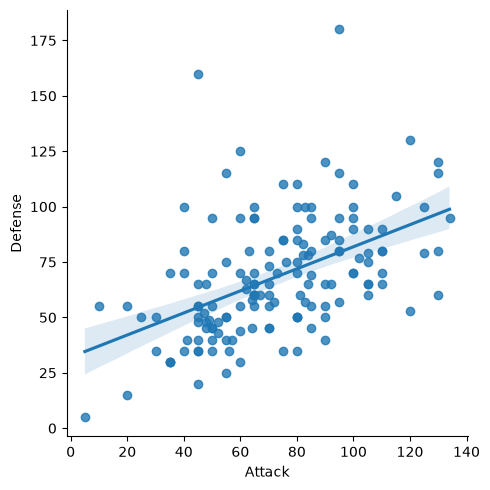

In [6]:
sns.lmplot(x="Attack", y="Defense", data=df);

In [7]:
# 6. No queremos ver la línea recta de la regresión lineal.
# prueba a añadir fit_reg a falso

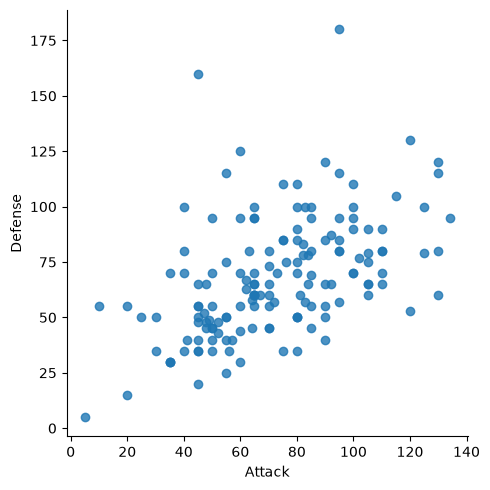

In [8]:
sns.lmplot(x="Attack", y="Defense", data=df, fit_reg=False);

In [9]:
# 7. Vamos a decir qué variable (columna del DataFrame) codifica los colores (hue)
# Que el hue sea el Stage

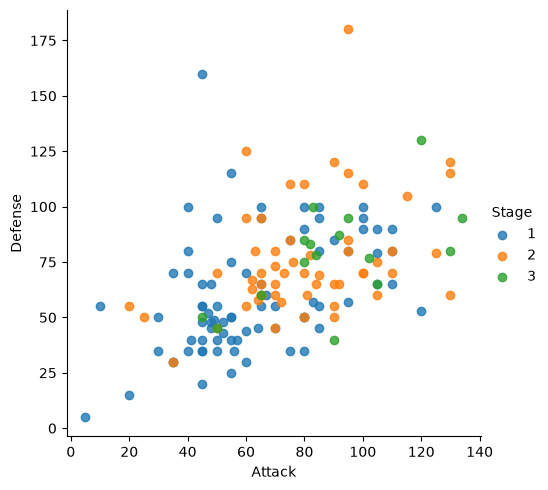

In [10]:
sns.lmplot(x="Attack", y="Defense", data=df, fit_reg=False, hue="Stage");

In [11]:
# 8. Limita el eje x entre 20 y 100

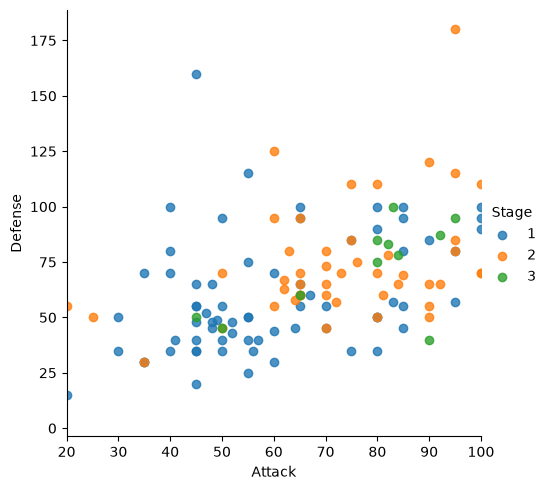

In [12]:
sns.lmplot(x="Attack", y="Defense", data=df, fit_reg=False, hue="Stage")
plt.xlim(20, 100);

# fija el rango del eje x  plt.xlim(-,-) 
 

In [13]:
# 9. Dibuja un diagrama de cajas con el dataframe

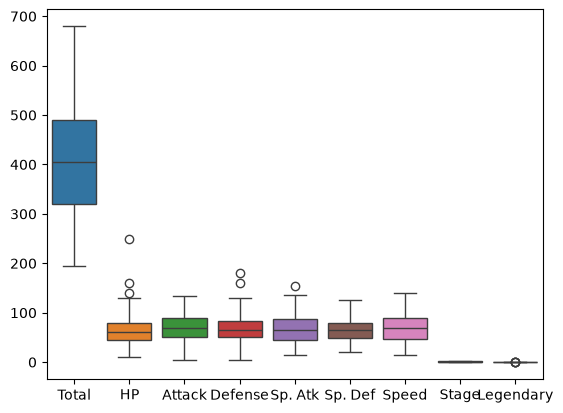

In [14]:
sns.boxplot(data=df);

In [15]:
# 10. No nos interesan las columnas Total, Stage ni Legendary
# Bórralos del DataFrame y vuelve a dibujar el diagrama de cajas

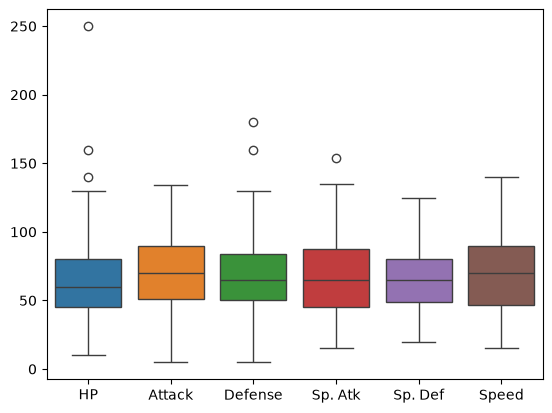

In [16]:
nuevo_df = df.drop(columns=["Total", "Stage", "Legendary"])

sns.boxplot(data=nuevo_df);

In [17]:
# 11. Mira cuántos 'Type 1' diferentes hay en el DataFrame

In [18]:
df["Type 1"].nunique()

15

In [19]:
# 12. Quédate del Dataframe solo con los 'Type 1' iguales a 'Grass', 'Fire' o 'Water'

In [20]:
df_grass_fire_water = df[df["Type 1"].isin(["Grass", "Fire", "Water"])]
df_grass_fire_water["Type 1"].value_counts()

Type 1
Water    28
Grass    12
Fire     12
Name: count, dtype: int64

In [21]:
# 13. Usa un estilo 'whitegrid'

In [22]:
sns.set_style("whitegrid")

# sns.set_style("") - el estilo

In [23]:
# 14. Pinta diagramas de violín con el DataFrame

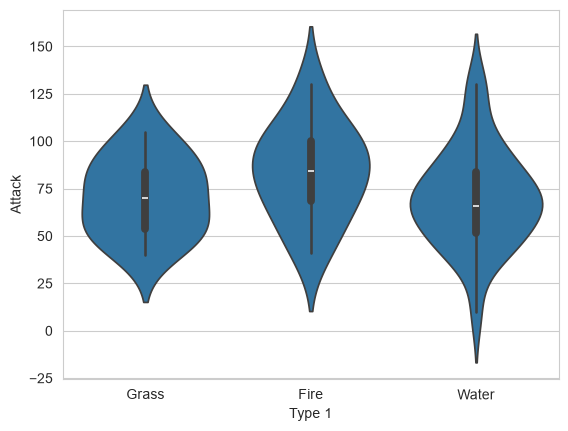

In [24]:
sns.violinplot(x="Type 1", y="Attack", data=df_grass_fire_water);

# categorica, numerica

In [25]:
# 15. Escribe una lista de colores con valores '#78C850', '#F08030',  '#6890F0'

In [26]:
pkmn_type_colors = ['#78C850',  # Grass (verde)
                    '#F08030',  # Fire (naranja)
                    '#6890F0']  # Water (azul)

In [27]:
# 16. Pinta de nuevo los diagramas de violín añadiendo esos colores en la paleta (palette)

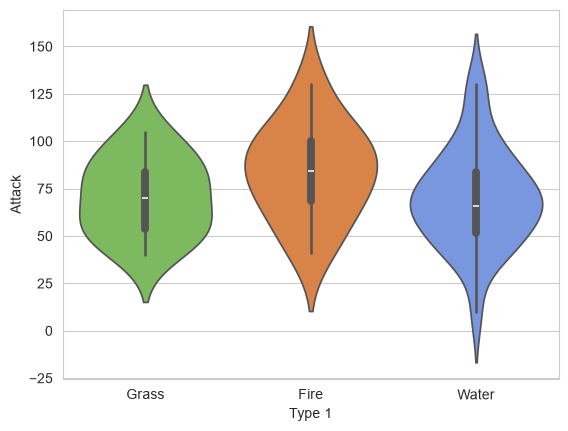

In [28]:
sns.violinplot(x="Type 1", y="Attack", data=df_grass_fire_water,
               hue="Type 1", palette=pkmn_type_colors, legend=False);

In [29]:
# 17. Con el diagrama de violín vemos la forma de la distribución, pero no sabemos si Grass tiene muchos puntos y Fire tiene muy pocos.
# Para ver esto, usamos el swarmplot.
# Pinta el último diagrama de violines pero con un swarmplot en lugar de un violin

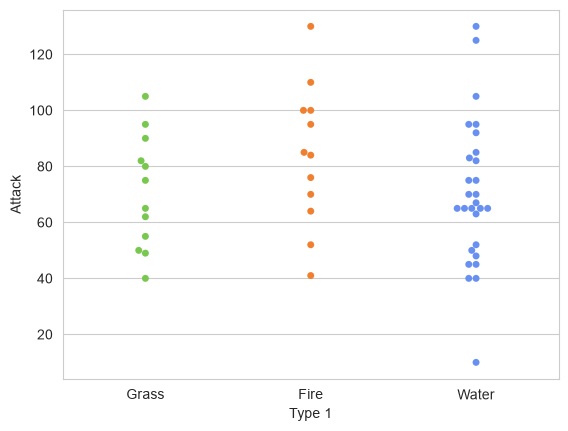

In [30]:
sns.swarmplot(x="Type 1", y="Attack", data=df_grass_fire_water,
              hue="Type 1", palette=pkmn_type_colors, legend=False);

In [31]:
# 18. Queremos ver los violines a la vez que los swarm, los podemos pintar juntos. 
# Elimina los diagramas de caja dentro de los violines con el parámetro inner = None y pon una transparencia de 0.9
# Pon un título con pyplot (como siempre)

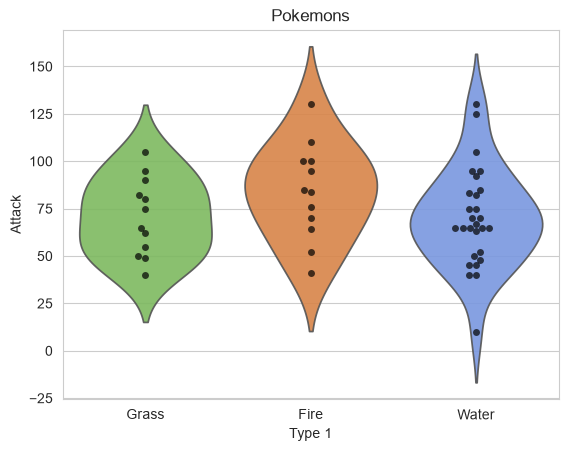

In [32]:
sns.violinplot(x="Type 1", y="Attack", data=df_grass_fire_water,
               hue="Type 1", palette=pkmn_type_colors, legend=False,
               inner=None,     # sin el boxplot interior
               alpha=0.9)      # transparencia

sns.swarmplot(x="Type 1", y="Attack", data=df_grass_fire_water,
              color="k",       # puntos negros
              alpha=0.7)

plt.title("Pokemons");


In [33]:
# 19. Veamos la función melt() de pandas. Melt toma los valores de varias columnas y los junta todos en una misma columna nueva.
# Dado un DataFrame, melt recibe varios parámetros:
# * qué columnas del DataFrame se quedan igual
# * qué nombres de columnas del dataframe pasan a ser una columna nueva
# * cómo queremos llamar esas nuevas columnas

# Primero recuerda el Dataframe df_grass_fire_water con las primeras 5 filas

In [34]:
df_grass_fire_water.head()

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False


In [35]:
# 20. Queremos dejar igual las variables 'Name' y 'Type 1'
# Queremos añadir una columa nueva cuyos valores sean las columnas que queremos apilar y que se llame 'New Column'
# Escribimos df_grass_fire_water.melt(id_vars=['Name', 'Type 1'], value_vars=[...], var_name='New Column')

In [46]:
# melt: dejo igual 'Name' y 'Type 1' y apilo las estadísticas en una sola columna
melted_df = df_grass_fire_water.melt(id_vars=["Name", "Type 1"],
                                     value_vars=["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"],
                                     var_name="New Column")
melted_df.head()

# cada Pokémon aparece 6 veces (una por estadística): 'New Column' dice cuál es y 'value' su valor

,Name,Type 1,New Column,value
0,Bulbasaur,Grass,HP,45
1,Ivysaur,Grass,HP,60
2,Venusaur,Grass,HP,80
3,Charmander,Fire,HP,39
4,Charmeleon,Fire,HP,58


In [36]:
# 21. Pintamos el swarmplot con el melted y entendemos la información

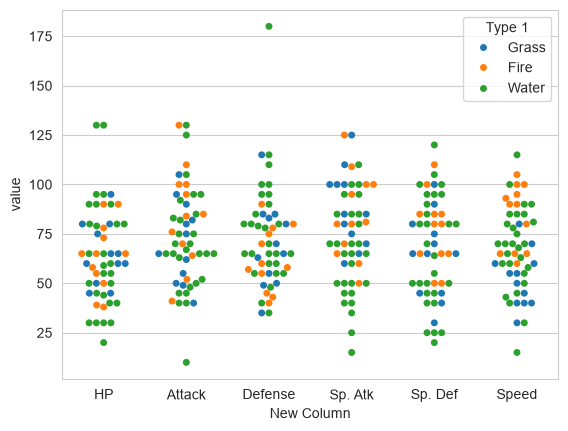

In [47]:
sns.swarmplot(x="New Column", y="value", data=melted_df, hue="Type 1");

# eje x: la estadística (categórica) / eje y: su valor (numérica) / color: el tipo

In [37]:
# 22. Basándote en el gráfico anterior, define el tamaño de la figura en (10,6) (usa plt)
# En el swarmplot añade el argumento dodge a True y usa la anterior paleta de colores Pokemon

# Dodge en inglés es "esquivar", ¿qué diferencia ves?

# Usando plt 
# fija el límite del eje Y entre 0 y 200
# fija la leyenda con bbox_to_anchor en upper left. Pista: upper left es el código 2 y se usa el parámetro loc.


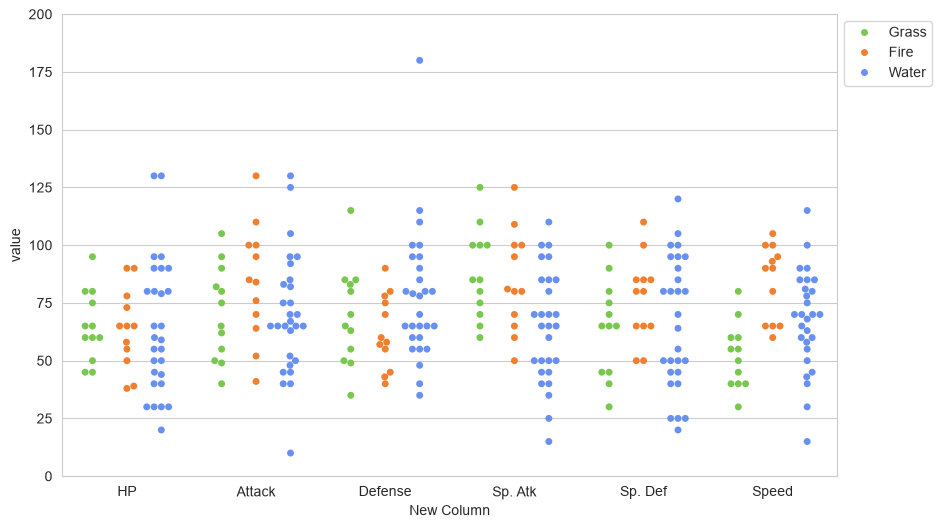

In [48]:
plt.figure(figsize=(10, 6))                      # tamaño de la figura

sns.swarmplot(x="New Column", y="value", data=melted_df,
              hue="Type 1", hue_order=["Grass", "Fire", "Water"],
              dodge=True,                             # separa los puntos de cada tipo
              palette=pkmn_type_colors)               # colores Pokémon (verde, naranja, azul)

plt.ylim(0, 200)                                     # rango del eje y
plt.legend(bbox_to_anchor=(1, 1), loc=2);            # leyenda fuera, arriba a la izquierda (loc=2 = upper left)

In [38]:
# Observa que incluso usando Seaborn, usamos Pyplot para trabajar con los ejes, la leyenda y el tamaño
# Lo importante es que Seaborn y Pyplot conviven bien juntos

Con dodge=True los puntos de cada tipo se separan en tres columnas dentro de cada estadística, en vez de mezclarse. Así se comparan mejor.

In [39]:
# 23. Mapas de calor
# Calcula las correlaciones del primer DataFrame original df
# Pista: las correlaciones se calculan con el método corr()
# Recuerda: las correlaciones miden entre dos variables, si varío una, cuánto me varía la otra (cómo están de relacionadas)

In [49]:
corr = df.corr(numeric_only=True)    # solo las columnas numéricas
corr

,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
Total,1.000000,0.576591,0.670939,0.508694,0.680745,0.774383,0.506950,0.504224,0.328412
HP,0.576591,1.000000,0.306768,0.119782,0.236649,0.490978,-0.040939,0.249207,0.172441
Attack,0.670939,0.306768,1.000000,0.491965,0.146312,0.369069,0.194701,0.361321,0.147486
Defense,0.508694,0.119782,0.491965,1.000000,0.187569,0.139912,-0.053252,0.270861,0.141576
Sp. Atk,0.680745,0.236649,0.146312,0.187569,1.000000,0.522907,0.411516,0.391712,0.334159
Sp. Def,0.774383,0.490978,0.369069,0.139912,0.522907,1.000000,0.392656,0.358308,0.215314
Speed,0.506950,-0.040939,0.194701,-0.053252,0.411516,0.392656,1.000000,0.240042,0.199969
Stage,0.504224,0.249207,0.361321,0.270861,0.391712,0.358308,0.240042,1.000000,-0.142508
Legendary,0.328412,0.172441,0.147486,0.141576,0.334159,0.215314,0.199969,-0.142508,1.000000


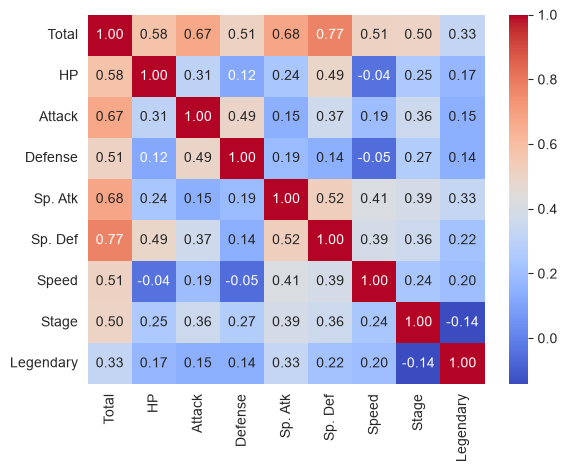

In [50]:
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm");

# annot=True escribe el valor en cada casilla

In [40]:
# ¿la correlación entre qué valores se encuentra?
# la autocorrelación es la correlación de una variable consigo misma, ¿qué aprecias?
# Encuentra dos variables que veas que están fuertemente relacionadas según la correlación
# Si tuvieras una matriz de correlación muy grande y te cobrasen por cada dato que lees, ¿qué harías?

- La correlación está entre -1 y 1.
- La autocorrelación (la diagonal) siempre vale 1, porque cada variable está totalmente relacionada consigo misma. Además, la matriz es simétrica.
- Variables muy relacionadas: Total con Sp. Def (0.77), Sp. Atk (0.68) y Attack (0.67), porque Total es la suma de todas las estadísticas.
- Si me cobrasen por cada dato, leería solo la mitad de la matriz (el triángulo superior sin la diagonal), porque la otra mitad es igual y la diagonal siempre es 1.

In [41]:
# 24. Pinta el histograma y la densidad de probabilidad del nivel de defensa usando el DataFrame original

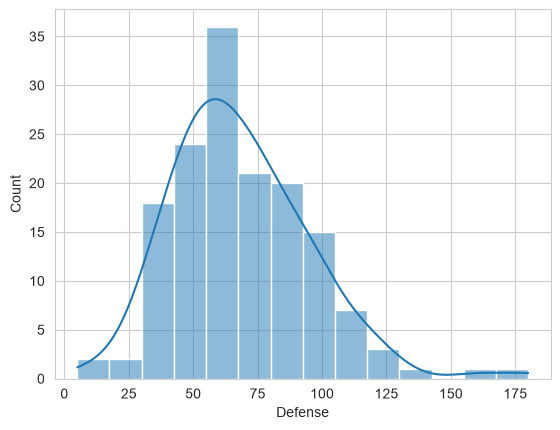

In [51]:
sns.histplot(df["Defense"], kde=True);

# histplot = histograma / kde=True añade la curva de densidad

In [42]:
# 25. Pinta un diagrama de barras de la columna 'Type 1' usando el DataFrame original
# Usa un sns.countplot
# Usa plt.xticks y gira las etiquetas

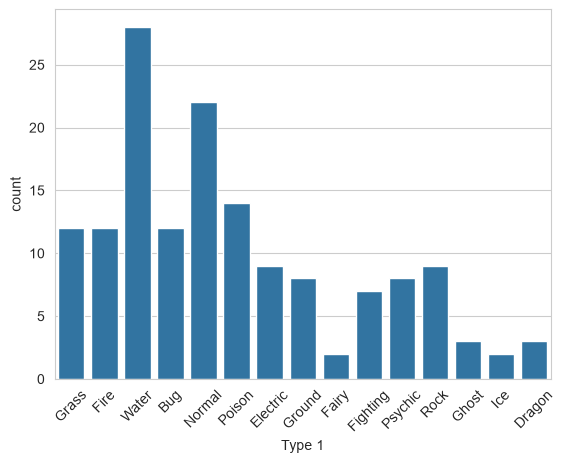

In [53]:
sns.countplot(x="Type 1", data=df)
plt.xticks(rotation=45);

# countplot cuenta cuántos hay de cada categoría / rotation gira las etiquetas

In [43]:
# 26. Usa catplot con el DataFrame original. Muestra el valor de Defense según el 'Type 1', muestra un subplot para legendarios y otro para no legendarios
# y divide los colores según el Type 2

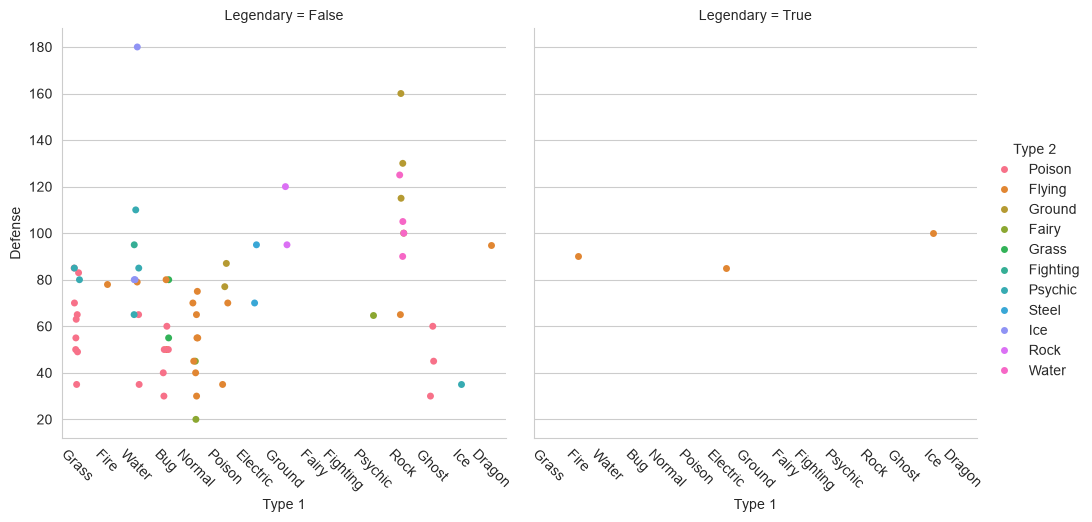

In [54]:
g = sns.catplot(x="Type 1", y="Defense", data=df,
                hue="Type 2",          # colores según el Type 2
                col="Legendary")       # un subplot para legendarios y otro para no legendarios
g.tick_params(axis="x", rotation=-45);

# con catplot hay varios subplots: tick_params gira las etiquetas de todos (plt.xticks solo giraría el último)

In [44]:
# 27. Muestra una función distribución de probabilidad con kdeplot (curvas de nivel) de la defensa respecto al ataque.
# Di un bin 2D donde caigan muchos puntos (ataque, defensa).

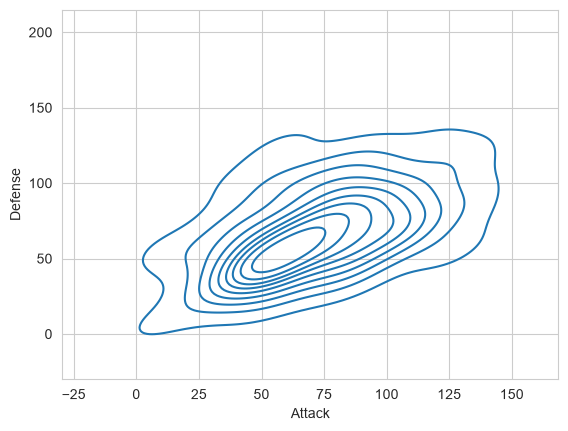

In [55]:
sns.kdeplot(x="Attack", y="Defense", data=df);

# curvas de nivel: cuanto más cerrados los anillos, más puntos hay en esa zona

La zona con más puntos es la del centro de los anillos: ataque entre 40 y 70 y defensa entre 40 y 60.

In [45]:
# 29. Pinta una distribución de probabilidad conjunta, pintando la defensa respecto al ataque del DataFrame original

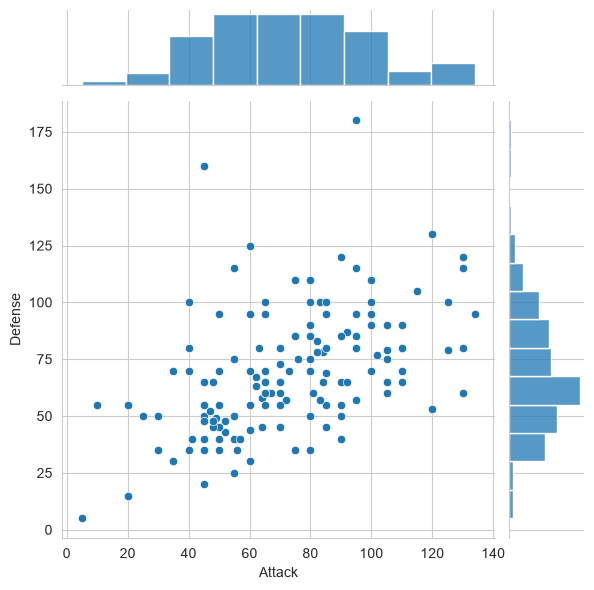

In [56]:
sns.jointplot(x="Attack", y="Defense", data=df);

# en el centro el scatter de defensa frente a ataque y en los bordes la distribución de cada variable